In [1]:
!pip install numpy pandas matplotlib seaborn scipy scikit-learn joblib

In [2]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import skew, kurtosis

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import joblib

print("Environment setup completed!")

Environment setup completed!


In [3]:
import os

DATA_DIR = "/content/drive/MyDrive/Schaeffler_Project/dataset"

os.makedirs(DATA_DIR, exist_ok=True)

In [4]:
!wget -O /content/IMS.zip "https://phm-datasets.s3.amazonaws.com/NASA/4.+Bearings.zip"

--2026-11-09 12:25:16--  https://phm-datasets.s3.amazonaws.com/NASA/4.+Bearings.zip
Resolving phm-datasets.s3.amazonaws.com (phm-datasets.s3.amazonaws.com)... 16.15.236.105, 52.217.133.74, 52.217.71.224, ...
Connecting to phm-datasets.s3.amazonaws.com (phm-datasets.s3.amazonaws.com)|16.15.236.105|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1075597174 (1.0G) [application/zip]
Saving to: ‘/content/IMS.zip’

/content/IMS.zip    100%[===================>]   1.00G  47.3MB/s    in 20s     

2026-11-09 12:25:37 (50.4 MB/s) - ‘/content/IMS.zip’ saved [1075597174/1075597174]



In [5]:
import zipfile

zip_path = "/content/IMS.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    for name in zip_ref.namelist()[:20]:
        print(name)

4. Bearings/
4. Bearings/IMS.7z


In [6]:
!pip install py7zr

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [py7zr]


In [7]:
import py7zr
import zipfile
import os

# Extract IMS.7z from the outer ZIP
with zipfile.ZipFile("/content/IMS.zip", "r") as z:
    z.extract("4. Bearings/IMS.7z", "/content")

# Open the 7z archive
archive = py7zr.SevenZipFile(
    "/content/4. Bearings/IMS.7z",
    mode="r"
)

# Inspect its contents
files = archive.getnames()

for file in files[:30]:
    print(file)

1st_test.rar
2nd_test.rar
3rd_test.rar
Readme Document for IMS Bearing Data.pdf


In [8]:
import os
import py7zr

output_dir = "/content/ims_selected"

os.makedirs(output_dir, exist_ok=True)

with py7zr.SevenZipFile(
    "/content/4. Bearings/IMS.7z",
    mode="r"
) as archive:

    archive.extract(
        path=output_dir,
        targets=["1st_test.rar"]
    )

print("First experiment extracted!")

First experiment extracted!


In [9]:
!apt-get update -qq
!apt-get install -y p7zip-full

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
p7zip-full is already the newest version (16.02+transitional.1).
0 upgraded, 0 newly installed, 0 to remove and 33 not upgraded.


In [12]:
!apt-get install -y unar

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  gnustep-base-common gnustep-base-runtime gnustep-common gnutls-bin libgc1
  libgnustep-base1.29 libgnutls-dane0t64 libobjc4 libunbound8 libwavpack1
  tzdata-legacy
Suggested packages:
  dns-root-data
The following NEW packages will be installed:
  gnustep-base-common gnustep-base-runtime gnustep-common gnutls-bin libgc1
  libgnustep-base1.29 libgnutls-dane0t64 libobjc4 libunbound8 libwavpack1
  tzdata-legacy unar
0 upgraded, 12 newly installed, 0 to remove and 33 not upgraded.
Need to get 4,323 kB of archives.
After this operation, 19.0 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/universe amd64 gnustep-common amd64 2.9.1-3build1 [38.4 kB]
Get:2 http://archive.ubuntu.com/ubuntu noble-updates/main amd64 tzdata-legacy all 2026e-0ubuntu0.24.04.1 [95.4 kB]
Get:3 http://archive.ubuntu.com/ubuntu nobl

In [13]:
!unar -f -o /content/ims_selected/1st_test \
"/content/ims_selected/1st_test.rar"

/content/ims_selected/1st_test.rar: RAR
  1st_test/2003.10.22.12.06.24  (1148716 B)... OK.
  1st_test/2003.10.22.12.09.13  (1149141 B)... OK.
  1st_test/2003.10.22.12.14.13  (1149766 B)... OK.
  1st_test/2003.10.22.12.19.13  (1149168 B)... OK.
  1st_test/2003.10.22.12.24.13  (1149152 B)... OK.
  1st_test/2003.10.22.12.29.13  (1149307 B)... OK.
  1st_test/2003.10.22.12.34.13  (1142313 B)... OK.
  1st_test/2003.10.22.12.39.13  (1149757 B)... OK.
  1st_test/2003.10.22.12.44.13  (1147587 B)... OK.
  1st_test/2003.10.22.12.49.13  (1148720 B)... OK.
  1st_test/2003.10.22.12.54.13  (1149938 B)... OK.
  1st_test/2003.10.22.12.59.13  (1148462 B)... OK.
  1st_test/2003.10.22.13.04.13  (1149504 B)... OK.
  1st_test/2003.10.22.13.09.13  (1149537 B)... OK.
  1st_test/2003.10.22.13.14.13  (1149289 B)... OK.
  1st_test/2003.10.22.13.19.13  (1148450 B)... OK.
  1st_test/2003.10.22.13.24.13  (1149161 B)... OK.
  1st_test/2003.10.22.13.29.13  (1149246 B)... OK.
  1st_test/2003.10.22.13.34.13  (1148857 B

In [14]:
import os

experiment_path = "/content/ims_selected/1st_test"

files = os.listdir(experiment_path)

print("Total recordings:", len(files))
print("First 10 recordings:", files[:10])

Total recordings: 1
First 10 recordings: ['1st_test']


In [15]:
import os

for root, dirs, files in os.walk("/content/ims_selected/1st_test"):
    print("Folder:", root)
    print("Number of files:", len(files))
    print("Subfolders:", dirs)

Folder: /content/ims_selected/1st_test
Number of files: 0
Subfolders: ['1st_test']
Folder: /content/ims_selected/1st_test/1st_test
Number of files: 2156
Subfolders: []


In [16]:
import os
import pandas as pd

DATA_PATH = "/content/ims_selected/1st_test/1st_test"

files = sorted(os.listdir(DATA_PATH))

print("Total recordings:", len(files))

# Load one vibration recording
sample_file = os.path.join(DATA_PATH, files[0])

df = pd.read_csv(
    sample_file,
    sep=r"\s+",
    header=None
)

print("\nDataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nData types:")
print(df.dtypes)


Total recordings: 2156

Dataset shape: (20480, 8)

First 5 rows:


,0,1,2,3,4,5,6,7
0,-0.022,-0.039,-0.183,-0.054,-0.105,-0.134,-0.129,-0.142
1,-0.105,-0.017,-0.164,-0.183,-0.049,0.029,-0.115,-0.122
2,-0.183,-0.098,-0.195,-0.125,-0.005,-0.007,-0.171,-0.071
3,-0.178,-0.161,-0.159,-0.178,-0.100,-0.115,-0.112,-0.078
4,-0.208,-0.129,-0.261,-0.098,-0.151,-0.205,-0.063,-0.066



Data types:
0    float64
1    float64
2    float64
3    float64
4    float64
5    float64
6    float64
7    float64
dtype: object


In [17]:
import os
import numpy as np
import pandas as pd

from scipy.stats import skew, kurtosis

DATA_PATH = "/content/ims_selected/1st_test/1st_test"

files = sorted(os.listdir(DATA_PATH))

def extract_features(signal):
    signal = np.asarray(signal, dtype=np.float64)

    rms = np.sqrt(np.mean(signal ** 2))

    return {
        "mean": np.mean(signal),
        "std": np.std(signal),
        "variance": np.var(signal),
        "rms": rms,
        "skewness": skew(signal),
        "kurtosis": kurtosis(signal),
        "peak_to_peak": np.ptp(signal),
        "crest_factor": np.max(np.abs(signal)) / (rms + 1e-10)
    }


records = []

for filename in files:

    file_path = os.path.join(DATA_PATH, filename)

    data = pd.read_csv(
        file_path,
        sep=r"\s+",
        header=None
    )

    row = {"timestamp": filename}

    for channel in range(data.shape[1]):

        features = extract_features(data.iloc[:, channel])

        for feature_name, value in features.items():

            row[f"ch{channel + 1}_{feature_name}"] = value

    records.append(row)


feature_df = pd.DataFrame(records)

print("Feature extraction completed!")
print("Dataset shape:", feature_df.shape)

display(feature_df.head())

Feature extraction completed!
Dataset shape: (2156, 65)


,timestamp,ch1_mean,ch1_std,ch1_variance,ch1_rms,ch1_skewness,ch1_kurtosis,ch1_peak_to_peak,ch1_crest_factor,ch2_mean,...,ch7_peak_to_peak,ch7_crest_factor,ch8_mean,ch8_std,ch8_variance,ch8_rms,ch8_skewness,ch8_kurtosis,ch8_peak_to_peak,ch8_crest_factor
0,2003.10.22.12.06.24,-0.094593,0.081122,0.006581,0.124614,-0.029993,1.069163,1.108,5.777850,-0.093880,...,0.662,3.788279,-0.094235,0.066380,0.004406,0.115267,0.008295,1.807990,0.845,4.086150
1,2003.10.22.12.09.13,-0.094903,0.079515,0.006323,0.123811,-0.070075,1.161552,1.042,5.282236,-0.093891,...,0.796,3.856767,-0.087946,0.064744,0.004192,0.109208,-0.053792,1.873189,0.900,5.741343
2,2003.10.22.12.14.13,-0.096187,0.080217,0.006435,0.125246,-0.041646,0.986286,0.940,4.974196,-0.095863,...,0.657,3.589583,-0.093106,0.065253,0.004258,0.113696,0.047138,1.429695,0.977,5.286029
3,2003.10.22.12.19.13,-0.095613,0.080825,0.006533,0.125197,0.005162,1.034294,1.055,4.776455,-0.095307,...,0.591,3.539356,-0.093244,0.066301,0.004396,0.114413,0.021106,1.378184,0.852,4.588643
4,2003.10.22.12.24.13,-0.095133,0.082034,0.006730,0.125618,-0.060196,1.110164,1.011,4.959475,-0.095495,...,0.591,3.412278,-0.093070,0.066279,0.004393,0.114258,0.008626,1.497653,0.871,4.568625


In [18]:
FEATURE_PATH = "/content/drive/MyDrive/Schaeffler_Project/dataset/bearing_features.csv"

feature_df.to_csv(FEATURE_PATH, index=False)

print("Feature dataset saved:", FEATURE_PATH)

Feature dataset saved: /content/drive/MyDrive/Schaeffler_Project/dataset/bearing_features.csv


In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

FEATURE_PATH = "/content/drive/MyDrive/Schaeffler_Project/dataset/bearing_features.csv"

feature_df = pd.read_csv(FEATURE_PATH)

print("Shape:", feature_df.shape)
print("Missing values:", feature_df.isnull().sum().sum())

display(feature_df.describe())

Shape: (2156, 65)
Missing values: 0


,ch1_mean,ch1_std,ch1_variance,ch1_rms,ch1_skewness,ch1_kurtosis,ch1_peak_to_peak,ch1_crest_factor,ch2_mean,ch2_std,...,ch7_peak_to_peak,ch7_crest_factor,ch8_mean,ch8_std,ch8_variance,ch8_rms,ch8_skewness,ch8_kurtosis,ch8_peak_to_peak,ch8_crest_factor
count,2156.000000,2156.000000,2156.000000,2156.000000,2156.000000,2156.000000,2156.000000,2156.000000,2156.000000,2156.000000,...,2156.000000,2156.000000,2156.000000,2156.000000,2156.000000,2156.000000,2156.000000,2156.000000,2156.000000,2156.000000
mean,-0.115946,0.098572,0.009745,0.152221,-0.038619,0.998084,1.177997,4.774991,-0.115703,0.088981,...,1.222874,4.794083,-0.112721,0.095248,0.009715,0.148647,0.027025,2.163801,1.314533,4.983893
std,0.005849,0.005344,0.001058,0.007184,0.030227,0.197341,0.107634,0.500901,0.005869,0.005293,...,0.750161,1.888144,0.008584,0.025358,0.005581,0.019971,0.084629,3.345336,0.713627,1.876049
min,-0.122302,0.079413,0.006306,0.123811,-0.137095,0.279632,0.822000,3.667271,-0.122835,0.069301,...,0.559000,2.790176,-0.220877,0.064231,0.004126,0.088488,-1.052101,0.481963,0.681000,2.815244
25%,-0.118046,0.096967,0.009403,0.152211,-0.058606,0.867872,1.104000,4.407684,-0.117809,0.087883,...,0.791000,3.747646,-0.114804,0.079062,0.006251,0.138657,-0.006347,1.045178,0.922000,4.014265
50%,-0.117486,0.099051,0.009811,0.153733,-0.038394,0.995836,1.175500,4.712527,-0.117206,0.090198,...,0.920000,4.167878,-0.114119,0.082986,0.006887,0.141214,0.024215,1.346757,1.062000,4.390173
75%,-0.116868,0.101151,0.010232,0.155258,-0.017576,1.123880,1.250000,5.063920,-0.116594,0.091836,...,1.443000,4.952207,-0.113379,0.109127,0.011909,0.159869,0.060125,1.888562,1.430250,5.088710
max,-0.093412,0.129741,0.016833,0.174975,0.071569,1.699493,1.533000,7.123804,-0.093747,0.106988,...,7.347000,19.449327,-0.041233,0.181056,0.032781,0.234522,1.076500,56.367171,7.122000,19.173927


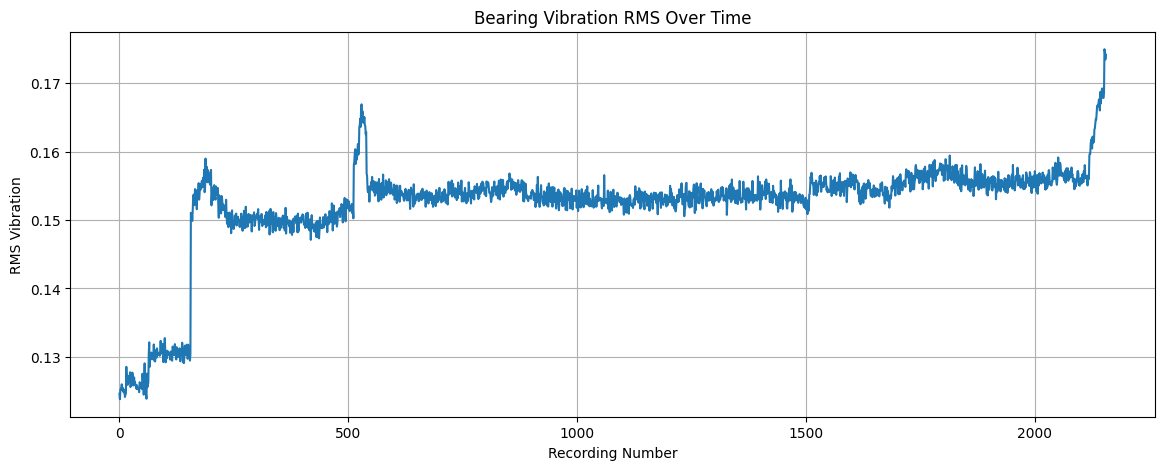

In [20]:
plt.figure(figsize=(14, 5))

plt.plot(feature_df["ch1_rms"])

plt.title("Bearing Vibration RMS Over Time")
plt.xlabel("Recording Number")
plt.ylabel("RMS Vibration")

plt.grid(True)
plt.show()

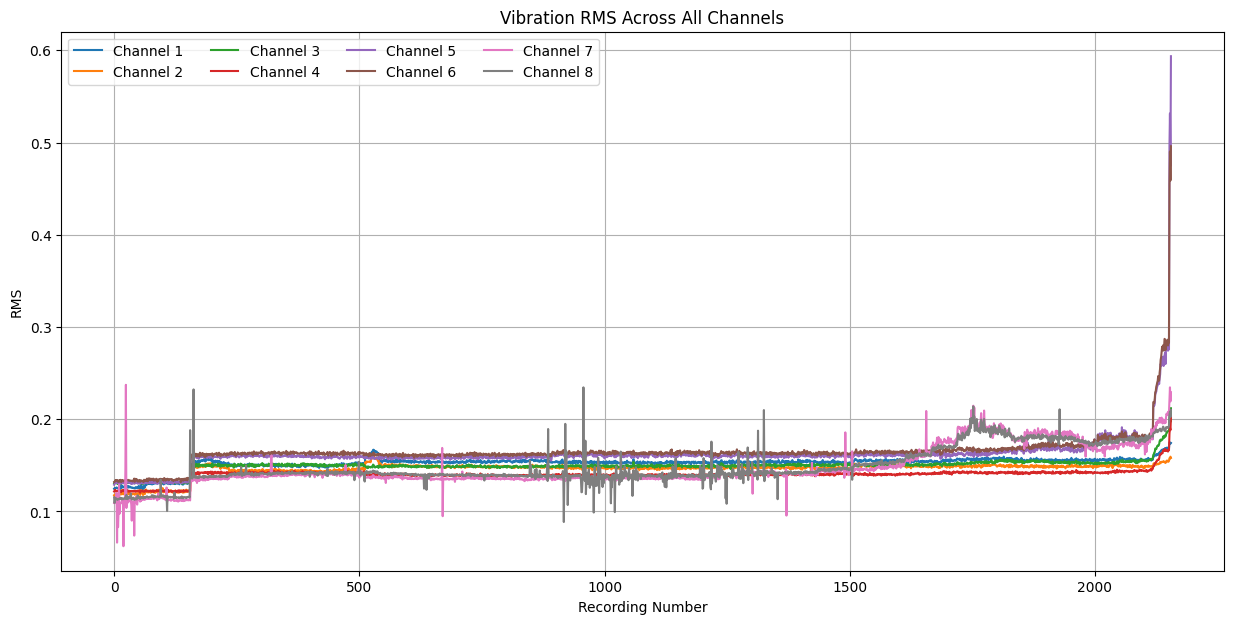

In [21]:
plt.figure(figsize=(15, 7))

for channel in range(1, 9):
    plt.plot(
        feature_df[f"ch{channel}_rms"],
        label=f"Channel {channel}"
    )

plt.title("Vibration RMS Across All Channels")
plt.xlabel("Recording Number")
plt.ylabel("RMS")
plt.legend(ncol=4)
plt.grid(True)
plt.show()

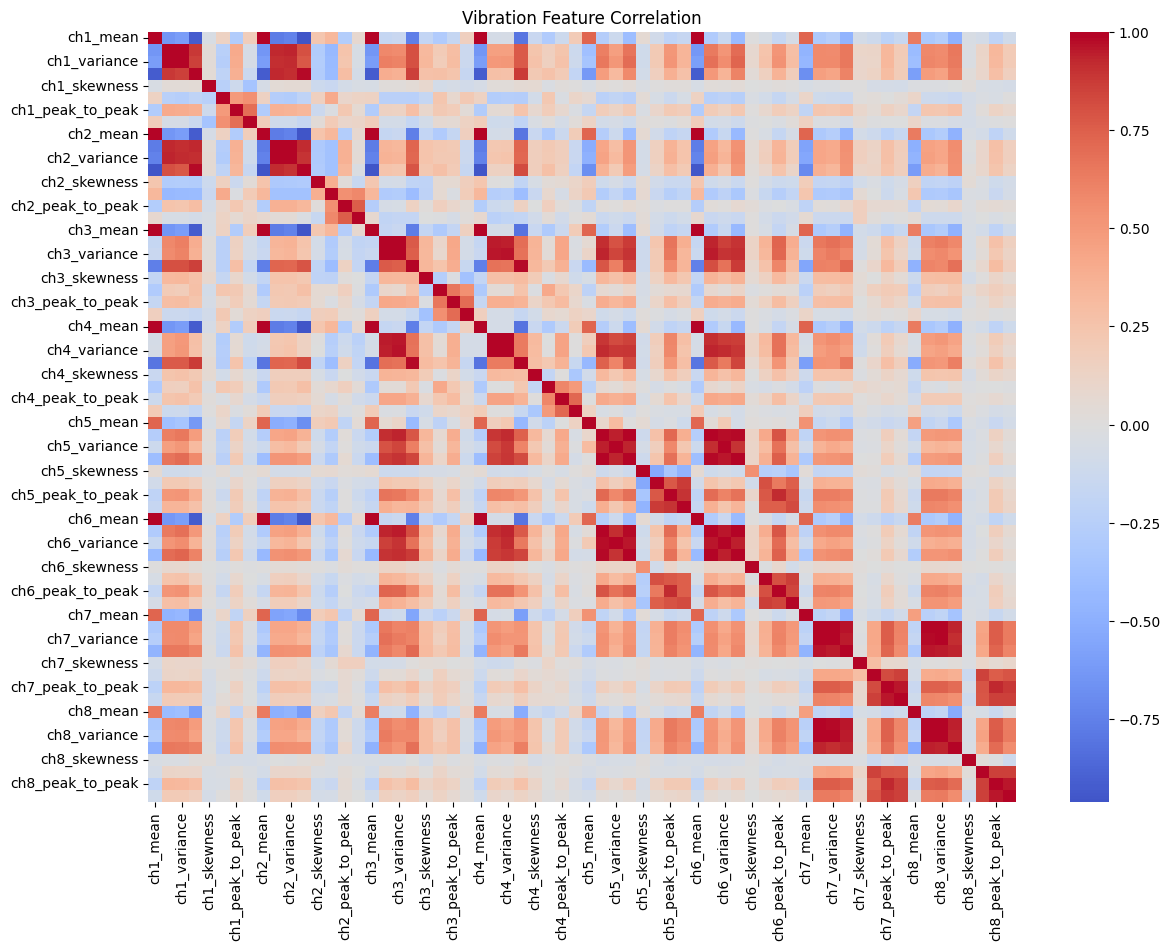

In [22]:
plt.figure(figsize=(14, 10))

corr = feature_df.drop(columns=["timestamp"]).corr()

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0
)

plt.title("Vibration Feature Correlation")
plt.show()

In [23]:
feature_variance = (
    feature_df
    .drop(columns=["timestamp"])
    .var()
    .sort_values(ascending=False)
)

display(feature_variance.head(15))

,0
ch5_kurtosis,30.377606
ch7_kurtosis,11.923666
ch8_kurtosis,11.191276
ch5_crest_factor,8.777746
ch7_crest_factor,3.565088
ch8_crest_factor,3.519560
ch6_crest_factor,2.329326
ch6_kurtosis,1.550599
ch5_peak_to_peak,0.936527
ch7_peak_to_peak,0.562742


In [24]:
import numpy as np
import pandas as pd

feature_df = pd.read_csv(
    "/content/drive/MyDrive/Schaeffler_Project/dataset/bearing_features.csv"
)

X = feature_df.drop(columns=["timestamp"])

X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

print("Features:", X.shape)

Features: (2156, 64)


In [25]:
split_index = int(len(X) * 0.20)

X_baseline = X.iloc[:split_index]

print("Baseline samples:", len(X_baseline))
print("Total samples:", len(X))

Baseline samples: 431
Total samples: 2156


In [26]:
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

model = Pipeline([
    ("scaler", StandardScaler()),

    ("isolation_forest", IsolationForest(
        n_estimators=200,
        contamination="auto",
        random_state=42
    ))
])

model.fit(X_baseline)

print("Anomaly detection model trained successfully!")

Anomaly detection model trained successfully!


In [27]:
predictions = model.predict(X)

feature_df["prediction"] = predictions

feature_df["status"] = feature_df["prediction"].map({
    1: "NORMAL",
    -1: "ANOMALY"
})

print(feature_df["status"].value_counts())

status
ANOMALY    1215
NORMAL      941
Name: count, dtype: int64


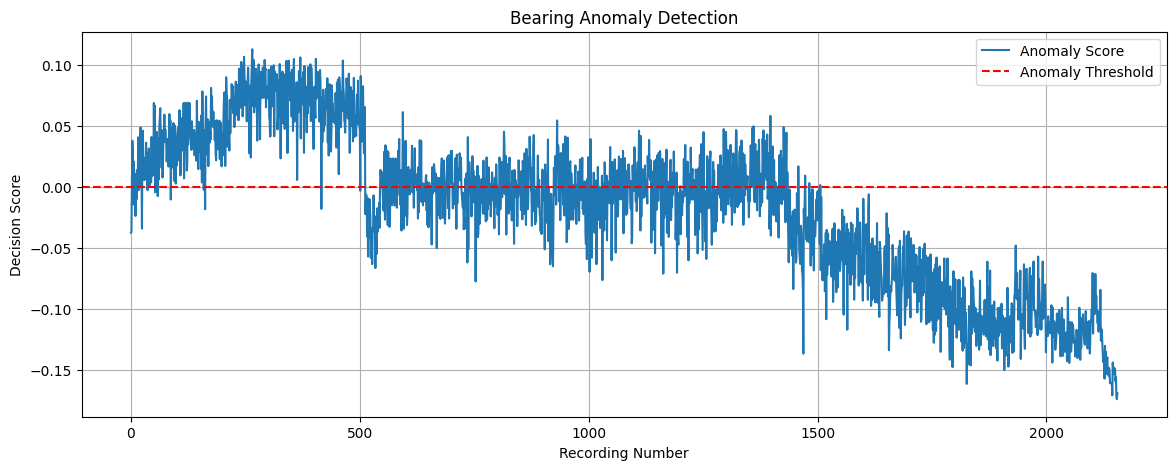

In [28]:
import matplotlib.pyplot as plt

scores = model.decision_function(X)

plt.figure(figsize=(14, 5))

plt.plot(scores, label="Anomaly Score")

plt.axhline(
    0,
    color="red",
    linestyle="--",
    label="Anomaly Threshold"
)

plt.title("Bearing Anomaly Detection")
plt.xlabel("Recording Number")
plt.ylabel("Decision Score")

plt.legend()
plt.grid()
plt.show()

In [30]:
import os
import joblib

MODEL_DIR = "/content/drive/MyDrive/Schaeffler_Project/models"

# Create directory if it doesn't exist
os.makedirs(MODEL_DIR, exist_ok=True)

MODEL_PATH = os.path.join(
    MODEL_DIR,
    "bearing_anomaly_model.joblib"
)

# Save trained model
joblib.dump(model, MODEL_PATH)

print("Model saved successfully!")
print("Location:", MODEL_PATH)

Model saved successfully!
Location: /content/drive/MyDrive/Schaeffler_Project/models/bearing_anomaly_model.joblib


In [31]:
import joblib
import os

MODEL_PATH = "/content/drive/MyDrive/Schaeffler_Project/models/bearing_anomaly_model.joblib"

loaded_model = joblib.load(MODEL_PATH)

print("Model loaded successfully!")

Model loaded successfully!


In [32]:
import pandas as pd
import numpy as np

DATA_PATH = "/content/ims_selected/1st_test/1st_test"

files = sorted(os.listdir(DATA_PATH))

# Select the last recording
sample_file = os.path.join(DATA_PATH, files[-1])

data = pd.read_csv(
    sample_file,
    sep=r"\s+",
    header=None
)

# Extract the same features used during training
features = {}

for channel in range(data.shape[1]):
    signal = data.iloc[:, channel].to_numpy(dtype=float)

    rms = np.sqrt(np.mean(signal ** 2))

    from scipy.stats import skew, kurtosis

    values = {
        "mean": np.mean(signal),
        "std": np.std(signal),
        "variance": np.var(signal),
        "rms": rms,
        "skewness": skew(signal),
        "kurtosis": kurtosis(signal),
        "peak_to_peak": np.ptp(signal),
        "crest_factor": np.max(np.abs(signal)) / (rms + 1e-10)
    }

    for name, value in values.items():
        features[f"ch{channel + 1}_{name}"] = value

sample_df = pd.DataFrame([features])

# Ensure the feature order matches training
sample_df = sample_df[X.columns]

prediction = loaded_model.predict(sample_df)[0]
anomaly_score = loaded_model.decision_function(sample_df)[0]

print("Prediction:", "NORMAL" if prediction == 1 else "ANOMALY")
print("Anomaly score:", anomaly_score)

Prediction: ANOMALY
Anomaly score: -0.1692788460316671


In [33]:
import os
import json
import joblib

MODEL_DIR = "/content/drive/MyDrive/Schaeffler_Project/models"

os.makedirs(MODEL_DIR, exist_ok=True)

# Save trained model
joblib.dump(
    model,
    f"{MODEL_DIR}/bearing_anomaly_model.joblib"
)

# Save feature names in their original order
with open(
    f"{MODEL_DIR}/feature_columns.json",
    "w"
) as f:
    json.dump(list(X.columns), f, indent=4)

print("Model and feature columns saved!")

Model and feature columns saved!


In [34]:
from google.colab import files

files.download(
    "/content/drive/MyDrive/Schaeffler_Project/models/bearing_anomaly_model.joblib"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [35]:
files.download(
    "/content/drive/MyDrive/Schaeffler_Project/models/feature_columns.json"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>